# Experiment 199 · Encoder compute and representation quality

**Complete** · Experiment 199 results saved · ETA 0h 00m 00s

Three held-out model seeds use two fresh paired masks and complementary A–B–A–B stream versions. All policies update the decoder every arrival with 50% broad-history replacement replay. Fixed 12.5%, 25%, and 50% use near-even periodic masks balanced between incoming and replayed images. Both adaptive policies match fixed 25% exactly in every 1,024-arrival group.

Every adaptive block begins with 64 arrivals at 25%. The shift rule compares observed RGB means in recent and preceding frames and spends extra updates after detected shifts. The learned rule reuses the E198 development-only reconstruction predictor and compares its predicted value of 50% updating with its development median. Both rules request a rate for the remaining 192 arrivals, then respect the quota.

Health averages every 256-arrival readout. Historical drift is mean cosine distance on the historical test bank relative to the encoder at that regime’s most recent exit. Online wall time includes data access, training and policy monitoring. The timer covers the online update loop. Evaluation readout time is recorded separately.

Completed deployments · 30/30. Completed frozen probes · 30.

## Time-averaged health and measured compute

| Policy | Matched runs | Current MSE | Historical MSE | RankMe | Retrieval | Historical drift | Encoder fraction | Train s | Control s | Wall s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | fixed 12.5% | 6 | 0.88072 | 0.85451 | 2.57639 | 0.61581 | 0.03323 | 12.5% | 107.07 | 0.00 | 107.10 | 
 | fixed 25% | 6 | 0.87835 | 0.85248 | 2.89782 | 0.70978 | 0.02591 | 25.0% | 110.14 | 0.00 | 110.17 | 
 | fixed 50% | 6 | 0.87664 | 0.85094 | 3.25768 | 0.75713 | 0.04821 | 50.0% | 122.46 | 0.00 | 122.49 | 
 | shift-responsive | 6 | 0.87850 | 0.85242 | 2.90401 | 0.71394 | 0.02776 | 25.0% | 118.66 | 0.40 | 119.11 | 
 | learned | 6 | 0.87876 | 0.85226 | 2.84620 | 0.71398 | 0.02621 | 25.0% | 110.93 | 1.83 | 112.82 | 

Positive gains favor the named policy. Paired 95% intervals use seed means across matched draws and stream versions.

| Policy | Reference | Objective gain [95% CI] | Retrieval gain | Historical drift reduction | Wall seconds saved [95% CI] |
| --- | --- | --- | --- | --- | --- |
 | shift-responsive | fixed 25% | +0.00016 [-0.00211, +0.00243] | +0.00416 [-0.03838, +0.04670] | -0.00184 [-0.01800, +0.01431] | -8.94599 [-49.13440, +31.24242] | 
 | learned | fixed 25% | +0.00012 [-0.00348, +0.00372] | +0.00420 [-0.06690, +0.07529] | -0.00030 [-0.00563, +0.00503] | -2.64818 [-4.77820, -0.51816] | 
 | fixed 12.5% | fixed 50% | -0.01089 [-0.01392, -0.00786] | -0.14131 [-0.17434, -0.10829] | +0.01497 [-0.04667, +0.07662] | +15.38919 [+3.49068, +27.28771] | 
 | fixed 25% | fixed 50% | -0.00399 [-0.00591, -0.00207] | -0.04735 [-0.06959, -0.02510] | +0.02230 [+0.00671, +0.03788] | +12.31869 [+6.20651, +18.43087] | 

| Policy | Windows | Requested boosts | Quota adjustments | Non-default allocations |
| --- | --- | --- | --- | --- |
 | shift-responsive | 432 | 21 | 0 | 411 | 
 | learned | 432 | 65 | 149 | 294 | 

## External representation quality

| Policy | Matched runs | scene | weather | lighting | pedestrian | Mean |
| --- | --- | --- | --- | --- | --- | --- |
 | fixed 12.5% | 6 | 41.23% | 44.14% | 96.38% | 58.65% | 60.10% | 
 | fixed 25% | 6 | 42.10% | 44.34% | 96.22% | 57.66% | 60.08% | 
 | fixed 50% | 6 | 43.02% | 45.99% | 96.54% | 57.86% | 60.85% | 
 | shift-responsive | 6 | 41.85% | 44.39% | 96.53% | 57.60% | 60.10% | 
 | learned | 6 | 41.76% | 44.60% | 96.38% | 57.29% | 60.01% | 

| Policy | Reference | Mean accuracy gain [95% CI] | scene | weather | lighting | pedestrian |
| --- | --- | --- | --- | --- | --- | --- |
 | shift-responsive | fixed 25% | +0.00016 [-0.01708, +0.01740] | -0.00247 [-0.01427, +0.00933] | +0.00051 [-0.01498, +0.01601] | +0.00311 [-0.02153, +0.02776] | -0.00052 [-0.02259, +0.02155] | 
 | learned | fixed 25% | -0.00072 [-0.01440, +0.01297] | -0.00340 [-0.02477, +0.01798] | +0.00257 [-0.00328, +0.00843] | +0.00160 [-0.02559, +0.02879] | -0.00365 [-0.01612, +0.00883] | 
 | fixed 12.5% | fixed 50% | -0.00754 [-0.01589, +0.00082] | -0.01790 [-0.03852, +0.00271] | -0.01852 [-0.04508, +0.00804] | -0.00154 [-0.03105, +0.02796] | +0.00781 [-0.00246, +0.01808] | 
 | fixed 25% | fixed 50% | -0.00774 [-0.01301, -0.00246] | -0.00926 [-0.02536, +0.00684] | -0.01646 [-0.03859, +0.00567] | -0.00314 [-0.02770, +0.02141] | -0.00208 [-0.01105, +0.00688] | 

## Preregistered success checks

Strong success requires positive interval-level health or mean downstream gain, runtime within 5%, and no task mean decline beyond two percentage points. Practical success requires at least 15% runtime savings and all paired task intervals above a two-point loss margin.

| Policy | Criterion | Result |
| --- | --- | --- |
 | shift-responsive | strong | unmet | 
 | learned | strong | unmet | 
 | fixed 12.5% | practical | unmet | 
 | fixed 25% | practical | unmet | 



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-compute-frontier')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


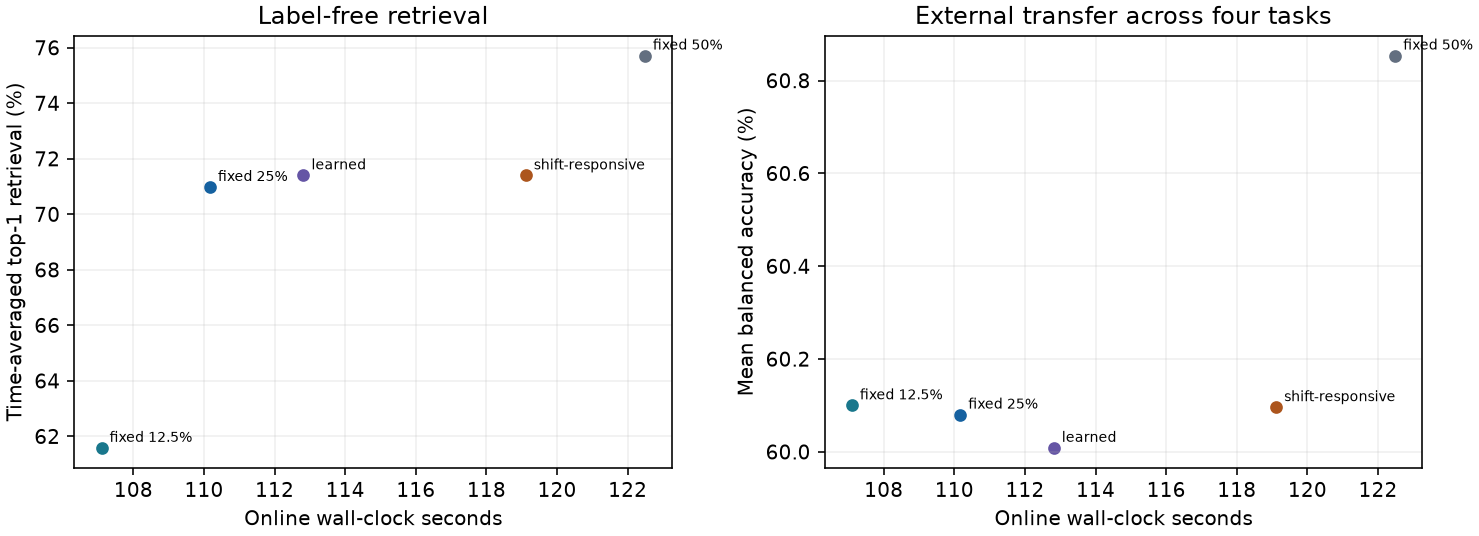